# Knowledge Graph `kg_diabet` — Bệnh đái tháo đường

**Nguồn dữ liệu:** Nhà thuốc Long Châu — `nhathuoclongchau.com.vn`
**Đích:** Neo4j database `kg-diabet`

---

## Section 1 — Giới thiệu & Mục tiêu

Notebook này chạy trọn vẹn pipeline xây dựng Knowledge Graph về bệnh tiểu đường:

| Bước | Nội dung | Đầu ra |
|------|----------|--------|
| 1 | Scraping Long Châu | `data/raw/articles.json`, `data/raw/drugs.json` |
| 2 | NLP / NER + trích xuất quan hệ | `data/processed/entities.json`, `relations.json` |
| 3 | Import vào Neo4j | Graph `kg-diabet` |
| 4 | Cypher queries khai thác | Bảng kết quả |

### Schema

```cypher
(:Disease)-[:HAS_SYMPTOM {frequency}]->(:Symptom)
(:Disease)-[:TREATED_BY {indication}]->(:Drug)
(:Disease)-[:DIAGNOSED_BY]->(:LabTest)
(:RiskFactor)-[:INCREASES_RISK_OF]->(:Disease)
(:Drug)-[:HAS_SIDE_EFFECT {frequency}]->(:SideEffect)
(:Drug)-[:BELONGS_TO]->(:DrugCategory)
(:Drug)-[:CONTRAINDICATED_WITH]->(:Drug)
(:Disease)-[:CAUSES]->(:Complication)
(:Complication)-[:DETECTED_BY]->(:LabTest)
```

> **Lưu ý y khoa:** dữ liệu trích xuất tự động từ nội dung phổ thông của một nhà
> thuốc bán lẻ, chỉ dùng cho mục đích học tập — không dùng để chẩn đoán/điều trị.

---
## Section 2 — Cài đặt & Kết nối Neo4j

Notebook nằm trong `notebook/` nên trước hết chuyển thư mục làm việc về gốc dự án
để dùng chung `config.py`, `lexicon.py` và thư mục `data/`.

In [1]:
# Cài dependencies (bỏ comment nếu chạy lần đầu)
# !pip install -r ../requirements.txt

In [2]:
import os, sys, json, importlib
from collections import Counter, defaultdict

# đưa working dir về gốc dự án
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import config
import lexicon

print("Thư mục làm việc :", os.getcwd())
print("Neo4j URI        :", config.NEO4J_URI)
print("Database         :", config.NEO4J_DATABASE)

Thư mục làm việc : C:\Users\Admin\Knowledge Graph kg_diabet
Neo4j URI        : neo4j://127.0.0.1:7687
Database         : kg-diabet


In [3]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
    config.NEO4J_URI, auth=(config.NEO4J_USER, config.NEO4J_PASSWORD)
)
driver.verify_connectivity()
print("Kết nối Neo4j thành công")

with driver.session(database="system") as s:
    for r in s.run("SHOW DATABASES YIELD name, currentStatus"):
        print(f"  - {r['name']:<12} {r['currentStatus']}")

Kết nối Neo4j thành công
  - kg-diabet    online
  - neo4j        online
  - system       online


In [4]:
import pandas as pd

def cypher_df(query, **params):
    """Chạy Cypher trên database kg-diabet và trả về DataFrame."""
    with driver.session(database=config.NEO4J_DATABASE) as session:
        records = list(session.run(query, **params))
    return pd.DataFrame([r.data() for r in records])

---
## Section 3 — Scraping Long Châu

Long Châu là ứng dụng **Next.js**: toàn bộ dữ liệu của trang nằm trong thẻ
`<script id="__NEXT_DATA__">` dưới dạng JSON, nên ta parse JSON thay vì bóc CSS
selector — vừa đầy đủ hơn, vừa không vỡ khi site đổi giao diện.

`robots.txt` của Long Châu **chặn** `/tim-kiem` và mọi URL `*?keyword=`, và trang
đó render sản phẩm bằng JavaScript (requests chỉ nhận mảng rỗng). Vì vậy pipeline
lấy URL từ các nguồn được phép crawl và render sẵn server-side:

* `sitemap_benh.xml` → trang bệnh (có sẵn mục *triệu chứng*, *nguyên nhân*, *yếu tố nguy cơ*, *chẩn đoán & điều trị*)
* `sitemap_baiviet1..4.xml` → bài viết chuyên đề tiểu đường
* `sitemap_thuoc.xml` lọc theo hoạt chất + trang danh mục `/thuoc/thuoc-tri-tieu-duong`

In [5]:
scraping = importlib.import_module("01_scraping")

# Chạy lại scraping? (mất ~10 phút vì có delay 1-3s giữa các request)
RERUN_SCRAPING = False

if RERUN_SCRAPING or not os.path.exists(config.ARTICLES_JSON):
    scraping.main()
else:
    print("Dùng lại dữ liệu đã scrape trong data/raw/ (đặt RERUN_SCRAPING=True để chạy lại)")

Dùng lại dữ liệu đã scrape trong data/raw/ (đặt RERUN_SCRAPING=True để chạy lại)


In [6]:
articles = json.load(open(config.ARTICLES_JSON, encoding="utf-8"))
drugs    = json.load(open(config.DRUGS_JSON,    encoding="utf-8"))

print(f"Bài viết & trang bệnh : {len(articles)}")
print(f"  trong đó trang bệnh : {sum(1 for a in articles if a['type'] == 'disease')}")
print(f"Thuốc                 : {len(drugs)}")

pd.DataFrame([{
    "title": a["title"][:60],
    "type": a["type"],
    "n_sections": len(a["sections"]),
    "n_chars": len(a["content"]),
} for a in articles]).head(10)

Bài viết & trang bệnh : 95
  trong đó trang bệnh : 15
Thuốc                 : 64


,title,type,n_sections,n_chars
0,"Đái tháo đường: Triệu chứng, nguyên nhân, chẩn...",disease,6,14941
1,Hạ đường huyết là gì? Nguyên nhân và cách phòn...,disease,6,6344
2,Tiểu đường thai kỳ: Dấu hiệu và cách điều trị,disease,6,10144
3,"Đường huyết cao: Dấu hiệu và cách kiểm soát, h...",disease,6,13646
4,"Tiểu đường tuýp 1: Nguyên nhân, triệu chứng, c...",disease,6,12478
5,"Tiểu đường tuýp 2 là gì? Nguyên nhân, triệu ch...",disease,6,10149
6,Bệnh thần kinh đái tháo đường là gì? Dấu hiệu ...,disease,6,10708
7,Bệnh thận đái tháo đường là gì? Cách phòng ngừ...,disease,6,8352
8,"Bệnh võng mạc tiểu đường: Triệu chứng, nguyên ...",disease,6,8623
9,Hạ đường huyết tiểu đường là gì? Dấu hiệu nhận...,disease,6,9450


In [7]:
# Xem thử một trang bệnh đã scrape
disease_page = next(a for a in articles if "type 2" in a["title"].lower() or "tuýp 2" in a["title"].lower())
print(disease_page["title"])
print(disease_page["url"])
print()
for key, text in disease_page["sections"].items():
    print(f"[{key}] {text[:220]}...\n")

Tiểu đường tuýp 2 là gì? Nguyên nhân, triệu chứng và cách điều trị
https://nhathuoclongchau.com.vn/benh/tieu-duong-tuyp-2.html

[description] Tiểu đường tuýp 2 (đái tháo đường type 2) là tình trạng bệnh xảy ra khi lượng glucose trong máu, còn gọi là đường huyết, cao quá mức. Glucose là nguồn năng lượng chính và chủ yếu đến từ thức ăn nạp vào cơ thể. Insulin , ...

[aetiologies] Nguyên nhân gây bệnh tiểu đường tuýp 2 chưa được xác minh rõ ràng, nhưng người ta cho rằng có sự tương tác giữa yếu tố gen và yếu tố môi trường như chế độ ăn uống, sinh hoạt,... góp phần hình thành nguyên nhân bệnh. Cơ c...

[symptom] Những dấu hiệu và triệu chứng của bệnh tiểu đường type 2 Bốn triệu chứng điển hình của tăng đường huyết là: Ăn nhiều, uống nhiều, tiểu nhiều, gầy nhiều. Nhưng đa phần các bệnh nhân tiểu đường type 2 không có các triệu ch...

[risk] Những ai có nguy cơ mắc phải bệnh tiểu đường type 2? Những đối tượng có nguy cơ mắc phải bệnh tiểu đường type 2 là: Nữ; Lớn tuổi; Thừa cân hay béo phì .

In [8]:
# Xem thử một thuốc đã scrape
sample_drug = next(d for d in drugs if "metformin" in (d["generic_name"] or "").lower())
for k in ["name", "generic_name", "dosage_form", "manufacturer", "price", "url"]:
    print(f"{k:<15}: {str(sample_drug[k])[:90]}")
print()
for k in ["indications", "side_effects", "contraindications"]:
    print(f"[{k}] {sample_drug[k][:250]}...\n")

name           : Thuốc Metformin 500MG Stella điều trị tiểu đường típ 2 (6 vỉ x 10 viên)
generic_name   : [{'id': 22316, 'ingredientId': 27124, 'shortDescription': '500mg', 'name': 'Metformin', 'i
dosage_form    : Viên nén bao phim
manufacturer   : Việt Nam
price          : None
url            : https://nhathuoclongchau.com.vn/thuoc/metformin-500-mg-stella-6-x10.html

[indications] Chỉ định Thuốc Mertformin 500 mg được chỉ định dùng trong các trường hợp sau: Điều trị đái tháo đường týp 2, đặc biệt ở bệnh nhân thừa cân, khi việc kiểm soát chế độ ăn và tập thể dục đơn thuần không đạt được hiệu quả trong việc kiểm soát glucose huy...

[side_effects] Khi sử dụng thuốc Metformin 500 mg bạn có thể gặp các tác dụng không mong muốn (ADR): Rất thường gặp (ADR ≥ 1/10) Tiêu hóa: Các rối loạn tiêu hóa như buồn nôn, nôn, tiêu chảy, đau bụng, chán ăn. Những tác dụng không mong muốn thường xảy ra nhất trong...

[contraindications] Trước khi sử dụng thuốc bạn cần đọc kỹ hướng dẫn sử dụng và tham khảo 

---
## Section 4 — NLP Extraction (NER + Relation Extraction)

Ba kỹ thuật kết hợp:

1. **Dictionary-based NER có canonical hoá** (`lexicon.py`). Thuật ngữ y khoa
   tiếng Việt là cụm từ đa âm tiết cố định nên từ điển cho độ chính xác cao hơn
   NER thống kê. Alias dài được ưu tiên khớp trước alias ngắn để
   *"đái tháo đường type 2"* không bị nuốt thành *"đái tháo đường"*.
2. **underthesea** — `sent_tokenize` tách câu, `word_tokenize` tách từ tiếng Việt.
3. **Luật sinh quan hệ** — section-aware (mục "Triệu chứng" của trang bệnh →
   `HAS_SYMPTOM`), regex pattern, và đồng xuất hiện cấp câu có *trigger word*.

In [9]:
from underthesea import sent_tokenize, word_tokenize

demo = ("Bệnh tiểu đường tuýp 2 thường có triệu chứng khát nước nhiều, đi tiểu nhiều "
        "và sụt cân. Bác sĩ chẩn đoán bằng xét nghiệm HbA1c và đường huyết lúc đói.")

print("Tách câu:")
for s in sent_tokenize(demo):
    print("  •", s)

print("\nTách từ:")
print(" ", word_tokenize(demo, format="text"))

Tách câu:


  • Bệnh tiểu đường tuýp 2 thường có triệu chứng khát nước nhiều, đi tiểu nhiều và sụt cân.
  • Bác sĩ chẩn đoán bằng xét nghiệm HbA1c và đường huyết lúc đói.

Tách từ:


 Bệnh tiểu_đường tuýp 2 thường có triệu_chứng khát nước nhiều , đi_tiểu nhiều và sụt cân . Bác_sĩ chẩn_đoán bằng xét_nghiệm HbA1c và đường_huyết lúc đói .


In [10]:
nlp = importlib.import_module("02_nlp_extraction")

print("Thực thể nhận diện được trong câu demo:")
for (etype, name), count in nlp.find_entities(demo).items():
    print(f"  {etype:<14} {name:<32} x{count}")

Thực thể nhận diện được trong câu demo:
  LabTest        Glucose huyết tương lúc đói      x1
  Disease        Đái tháo đường type 2            x1
  Symptom        Đi tiểu nhiều                    x1
  Symptom        Khát nước nhiều                  x1
  Symptom        Sụt cân không rõ nguyên nhân     x1
  LabTest        HbA1c                            x1


In [11]:
# Minh hoạ canonical hoá: nhiều cách viết -> cùng một node
for variant in ["tiểu đường tuýp 2", "đái tháo đường type 2", "tiểu đường loại 2",
                "đái tháo đường không phụ thuộc insulin", "tiểu đường thai kỳ"]:
    found = list(nlp.find_entities(variant, {"Disease"}))
    print(f"  {variant:<45} -> {found[0][1] if found else '(không khớp)'}")

  tiểu đường tuýp 2                             -> Đái tháo đường type 2
  đái tháo đường type 2                         -> Đái tháo đường type 2
  tiểu đường loại 2                             -> Đái tháo đường type 2
  đái tháo đường không phụ thuộc insulin        -> Đái tháo đường type 2
  tiểu đường thai kỳ                            -> Đái tháo đường thai kỳ


In [12]:
# Chạy toàn bộ Bước 2
nlp.main()

BUOC 2 - NLP EXTRACTION
Nap 95 bai viet, 64 thuoc
underthesea word_tokenize: 269 token tren mau 1500 ky tu


  ...da xu ly 20/95 bai viet


  ...da xu ly 40/95 bai viet


  ...da xu ly 60/95 bai viet


  ...da xu ly 80/95 bai viet


  ...da xu ly 20/64 thuoc
  ...da xu ly 40/64 thuoc


  ...da xu ly 60/64 thuoc

Ket qua trich xuat:
  diseases         8
  symptoms         15
  drugs            84
  lab_tests        11
  risk_factors     15
  complications    12
  side_effects     31
  drug_categories  9
  relations        1172

Quan he theo loai:
  HAS_SIDE_EFFECT        593
  BELONGS_TO             135
  CONTRAINDICATED_WITH   124
  TREATED_BY             91
  INCREASES_RISK_OF      70
  HAS_SYMPTOM            55
  DIAGNOSED_BY           43
  CAUSES                 43
  DETECTED_BY            18

-> C:\Users\Admin\Knowledge Graph kg_diabet\data\processed\entities.json
-> C:\Users\Admin\Knowledge Graph kg_diabet\data\processed\relations.json


In [13]:
entities  = json.load(open(config.ENTITIES_JSON,  encoding="utf-8"))
relations = json.load(open(config.RELATIONS_JSON, encoding="utf-8"))

pd.DataFrame(
    [(k, len(v)) for k, v in entities.items()],
    columns=["entity_type", "count"]
).sort_values("count", ascending=False)

,entity_type,count
2,drugs,84
6,side_effects,31
4,risk_factors,15
1,symptoms,15
5,complications,12
3,lab_tests,11
7,drug_categories,9
0,diseases,8


In [14]:
pd.DataFrame(
    Counter(r["relation"] for r in relations).most_common(),
    columns=["relation", "count"]
)

,relation,count
0,HAS_SIDE_EFFECT,593
1,BELONGS_TO,135
2,CONTRAINDICATED_WITH,124
3,TREATED_BY,91
4,INCREASES_RISK_OF,70
5,HAS_SYMPTOM,55
6,DIAGNOSED_BY,43
7,CAUSES,43
8,DETECTED_BY,18


In [15]:
# Vài quan hệ mẫu
pd.DataFrame([{
    "from": r["from_name"][:38],
    "rel": r["relation"],
    "to": r["to_name"][:34],
    "props": str(r["properties"])[:44],
} for r in relations if r["relation"] in ("HAS_SYMPTOM", "CAUSES", "INCREASES_RISK_OF")][:20])

,from,rel,to,props
0,Đái tháo đường,HAS_SYMPTOM,Khát nước nhiều,{'frequency': 'không rõ'}
1,Đái tháo đường,HAS_SYMPTOM,Đi tiểu nhiều,{'frequency': 'không rõ'}
2,Đái tháo đường,HAS_SYMPTOM,Đói thường xuyên,{'frequency': 'không rõ'}
3,Đái tháo đường,HAS_SYMPTOM,Sụt cân không rõ nguyên nhân,{'frequency': 'không rõ'}
4,Đái tháo đường,HAS_SYMPTOM,Mệt mỏi,{'frequency': 'không rõ'}
5,Tiền sử gia đình / di truyền,INCREASES_RISK_OF,Đái tháo đường,{}
6,Hội chứng buồng trứng đa nang,INCREASES_RISK_OF,Đái tháo đường,{}
7,Rối loạn lipid máu,INCREASES_RISK_OF,Đái tháo đường,{}
8,Tăng huyết áp,INCREASES_RISK_OF,Đái tháo đường,{}
9,Ít vận động,INCREASES_RISK_OF,Đái tháo đường,{}


---
## Section 5 — Import vào Neo4j

Toàn bộ dùng `MERGE` + `UNWIND` theo batch: chạy lại nhiều lần **không** nhân bản
node/quan hệ. Đặt `RESET = True` nếu muốn xoá sạch database trước khi nạp.

In [16]:
imp = importlib.import_module("03_import_neo4j")

RESET = True   # xoá sạch kg-diabet trước khi import

with driver.session(database=config.NEO4J_DATABASE) as session:
    if RESET:
        session.run("MATCH (n) DETACH DELETE n")
        print("Đã xoá dữ liệu cũ.\n")

    print("Import nodes:")
    imp.import_nodes(session, entities)

    print("\nImport relationships:")
    imp.import_relations(session, relations)

    print("\nTạo index:")
    imp.create_indexes(session)

Đã xoá dữ liệu cũ.

Import nodes:
  Disease        8 node
  Symptom        15 node
  Drug           84 node
  LabTest        11 node
  RiskFactor     15 node
  Complication   12 node
  SideEffect     31 node
  DrugCategory   9 node

Import relationships:
  BELONGS_TO             135 quan he
  CAUSES                 43 quan he


  CONTRAINDICATED_WITH   124 quan he
  DETECTED_BY            18 quan he
  DIAGNOSED_BY           43 quan he


  HAS_SIDE_EFFECT        593 quan he
  HAS_SYMPTOM            55 quan he
  INCREASES_RISK_OF      70 quan he
  TREATED_BY             91 quan he

Tạo index:
  da tao/kiem tra 8 index


---
## Section 6 — Thống kê Knowledge Graph

In [17]:
df_nodes = cypher_df("""
    MATCH (n) RETURN labels(n)[0] AS label, count(n) AS count ORDER BY count DESC
""")
df_nodes

,label,count
0,Drug,84
1,SideEffect,31
2,Symptom,15
3,RiskFactor,15
4,Complication,12
5,LabTest,11
6,DrugCategory,9
7,Disease,8


In [18]:
df_rels = cypher_df("""
    MATCH ()-[r]->() RETURN type(r) AS rel_type, count(r) AS count ORDER BY count DESC
""")
df_rels

,rel_type,count
0,HAS_SIDE_EFFECT,593
1,BELONGS_TO,135
2,CONTRAINDICATED_WITH,124
3,TREATED_BY,91
4,INCREASES_RISK_OF,70
5,HAS_SYMPTOM,55
6,CAUSES,43
7,DIAGNOSED_BY,43
8,DETECTED_BY,18


In [19]:
print(f"Tổng số node     : {df_nodes['count'].sum()}")
print(f"Tổng số quan hệ  : {df_rels['count'].sum()}")

Tổng số node     : 185
Tổng số quan hệ  : 1172


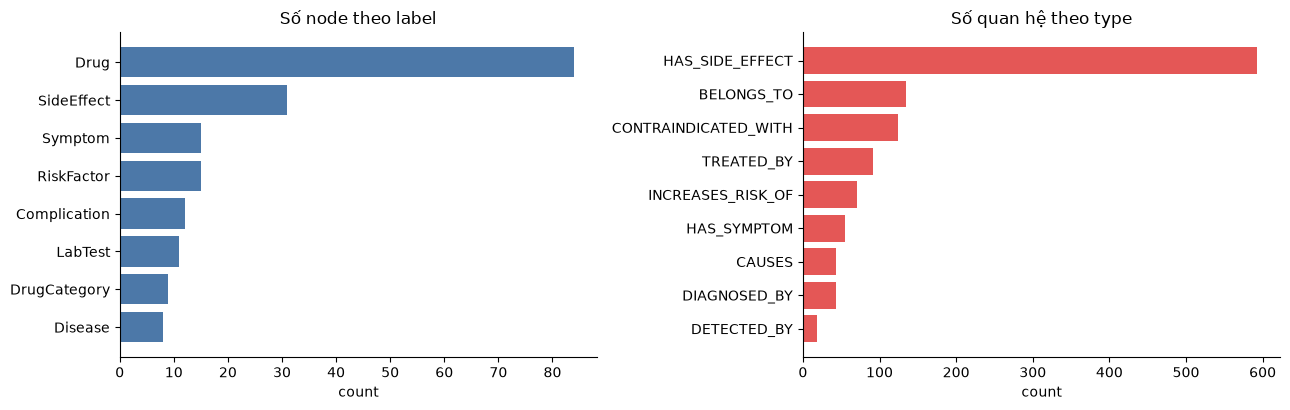

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].barh(df_nodes["label"][::-1], df_nodes["count"][::-1], color="#4C78A8")
axes[0].set_title("Số node theo label")
axes[0].set_xlabel("count")

axes[1].barh(df_rels["rel_type"][::-1], df_rels["count"][::-1], color="#E45756")
axes[1].set_title("Số quan hệ theo type")
axes[1].set_xlabel("count")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## Section 7 — Cypher Queries & Kết quả

15 query trong `04_queries.py` được định nghĩa dưới dạng danh sách `QUERIES`,
nên có thể chạy lại ngay trong notebook và hiển thị bằng DataFrame.

In [21]:
queries = importlib.import_module("04_queries")

pd.DataFrame([{"id": q["id"], "title": q["title"]} for q in queries.QUERIES])

,id,title
0,Q1,Triệu chứng của từng thể đái tháo đường
1,Q2,Thuốc điều trị đái tháo đường type 2 (giá chỉ ...
2,Q3,Xét nghiệm dùng để chẩn đoán mỗi bệnh
3,Q4,Yếu tố nguy cơ làm tăng khả năng mắc bệnh
4,Q5,Tác dụng phụ của các thuốc chứa Metformin
5,Q6,Biến chứng của bệnh đái tháo đường
6,Q7,Thuốc theo nhóm dược lý
7,Q8,Bệnh có triệu chứng 'Khát nước nhiều' được điề...
8,Q9,Đường đi RiskFactor -> Disease -> Complication
9,Q10,Thống kê tổng quan Knowledge Graph


In [22]:
def run(qid):
    spec = next(q for q in queries.QUERIES if q["id"] == qid)
    print(f"{spec['id']}. {spec['title']}")
    return cypher_df(spec["cypher"])

run("Q1")

Q1. Triệu chứng của từng thể đái tháo đường


,disease,n_symptoms,symptoms
0,Đái tháo đường,12,"[Buồn nôn, Chóng mặt, Khát nước nhiều, Mệt mỏi..."
1,Hạ đường huyết,8,"[Buồn nôn, Chóng mặt, Mệt mỏi, Mờ mắt, Nôn, Đa..."
2,Đái tháo đường type 1,8,"[Buồn nôn, Khát nước nhiều, Mệt mỏi, Mờ mắt, S..."
3,Đái tháo đường type 2,8,"[Buồn nôn, Khát nước nhiều, Mệt mỏi, Mờ mắt, T..."
4,Tăng đường huyết,6,"[Buồn nôn, Khát nước nhiều, Mờ mắt, Nôn, Đi ti..."
5,Tiền đái tháo đường,5,"[Chậm lành vết thương, Khát nước nhiều, Mờ mắt..."
6,Đái tháo đường thai kỳ,4,"[Khát nước nhiều, Mệt mỏi, Mờ mắt, Đi tiểu nhiều]"
7,Đái tháo đường ở trẻ em,4,"[Buồn nôn, Mệt mỏi, Mờ mắt, Đi tiểu nhiều]"


In [23]:
run("Q2")

Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `price` does not exist in database `kg-diabet`. Verify that the spelling is correct.', position=<SummaryInputPosition line=8, column=25, offset=325>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 325, 'line': 8, 'column': 25}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n            MATCH (d:Disease)-[:TREATED_BY]->(drug:Drug)\n            WHERE d.name CONTAINS "type 2"\n            RETURN drug.name AS drug,\n                   drug.dosage_form AS dosage_form,\n                   drug.specification AS specification,\n                   drug.manufacturer AS manufacturer,\n   

Q2. Thuốc điều trị đái tháo đường type 2 (giá chỉ có với thuốc không kê đơn)


,drug,dosage_form,specification,manufacturer,price
0,Bút tiêm Humalog Mix 75/25 KwixPen điều trị đá...,Hỗn dịch tiêm trong bút tiêm nạp sẵn,Hộp 5 Cây x 3ml,Pháp,None
1,Bút tiêm Insulatard FlexPen 100IU/ml Novo Nord...,Hỗn dịch tiêm trong bút tiêm nạp sẵn,Hộp 5 Cây x 3ml,Đan Mạch,None
2,Bút tiêm NovoMix 30 FlexPen Novo Nordisk điều ...,Hỗn dịch tiêm trong bút tiêm nạp sẵn,Hộp 5 Cây x 3ml,Đan Mạch,None
3,Hỗn dịch tiêm Mixtard 30 Novo Nordisk điều trị...,Hỗn dịch tiêm,Chai x 10ml,Đan Mạch,None
4,Thuốc A.T Sitagliptin 100 mg An Thiên cải thiệ...,Viên nén bao phim,Hộp 3 Vỉ x 10 Viên,Việt Nam,None
5,Thuốc A.T Vildagliptin 50mg An Thiên điều trị ...,Viên nén,Hộp 3 Vỉ x 10 Viên,Việt Nam,None
6,Thuốc Acarbose 50 SaVi điều trị đái tháo đường...,Viên nén bao phim,Hộp 10 Vỉ x 10 Viên,Việt Nam,None
7,Thuốc Acarbose Friulchem 50mg Famar hỗ trợ điề...,Viên nén,Hộp 9 Vỉ x 10 Viên,Ý,None
8,Thuốc DAPAGLIFLOZIN TABLET 10MG Macleods điều ...,Viên nén bao phim,Hộp 3 Vỉ x 10 Viên,Ấn Độ,None
9,Thuốc Fordia MR 500mg United điều trị đái tháo...,Viên nén bao phim giải phóng có kiểm soát,Hộp 6 Vỉ x 10 Viên,Việt Nam,None


In [24]:
run("Q3")

Q3. Xét nghiệm dùng để chẩn đoán mỗi bệnh


,disease,lab_tests
0,Đái tháo đường,"[C-peptide, Creatinin máu, Glucose huyết tương..."
1,Đái tháo đường type 2,"[Glucose huyết tương lúc đói, Glucose máu bất ..."
2,Hạ đường huyết,"[C-peptide, Glucose huyết tương lúc đói, HbA1c..."
3,Đái tháo đường type 1,"[Glucose máu bất kỳ, HbA1c, Insulin máu, Nghiệ..."
4,Đái tháo đường ở trẻ em,"[C-peptide, Glucose huyết tương lúc đói, HbA1c..."
5,Tăng đường huyết,"[Glucose huyết tương lúc đói, HbA1c, Nghiệm ph..."
6,Đái tháo đường thai kỳ,"[Glucose huyết tương lúc đói, Nghiệm pháp dung..."
7,Tiền đái tháo đường,"[HbA1c, Xét nghiệm đường huyết]"


In [25]:
run("Q4")

Q4. Yếu tố nguy cơ làm tăng khả năng mắc bệnh


,risk_factor,n_diseases,diseases
0,Béo phì,8,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
1,Thừa cân,8,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
2,Tiền sử gia đình / di truyền,8,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
3,Ít vận động,7,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
4,Rối loạn lipid máu,6,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
5,Tăng huyết áp,6,"[Hạ đường huyết, Tiền đái tháo đường, Tăng đườ..."
6,Stress,5,"[Hạ đường huyết, Tăng đường huyết, Đái tháo đư..."
7,Chế độ ăn nhiều đường,4,"[Hạ đường huyết, Tăng đường huyết, Đái tháo đư..."
8,Hút thuốc lá,4,"[Tăng đường huyết, Đái tháo đường, Đái tháo đư..."
9,Hội chứng buồng trứng đa nang,4,"[Tiền đái tháo đường, Đái tháo đường, Đái tháo..."


In [26]:
run("Q5")

Q5. Tác dụng phụ của các thuốc chứa Metformin


,drug,side_effects
0,Thuốc Fordia MR 500mg United điều trị đái tháo...,"[Buồn nôn (thường gặp), Chóng mặt (thường gặp)..."
1,Thuốc Galvus Met 50mg/1000mg Novartis hỗ trợ đ...,"[Buồn nôn (ít gặp), Chóng mặt (thường gặp), Gi..."
2,Thuốc Galvus Met 50mg/500mg Novartis điều trị ...,"[Buồn nôn (ít gặp), Chóng mặt (thường gặp), Gi..."
3,Thuốc Galvus Met 50mg/850mg Novartis hỗ trợ đi...,"[Buồn nôn (ít gặp), Chóng mặt (thường gặp), Gi..."
4,Thuốc Glucophage 1000mg Merck điều trị đái th...,"[Buồn nôn (thường gặp), Giảm vitamin B12 (hiếm..."
5,Thuốc Glucophage 500mg Merck điều trị đái thá...,"[Buồn nôn (hiếm gặp), Chán ăn (hiếm gặp), Giảm..."
6,Thuốc Glucophage 850mg Merck điều trị đái thá...,"[Buồn nôn (hiếm gặp), Chán ăn (hiếm gặp), Giảm..."
7,Thuốc Glucophage XR 1000mg Merck điều trị tiểu...,"[Buồn nôn (thường gặp), Chán ăn (thường gặp), ..."
8,Thuốc Glucophage XR 500mg Merck điều trị tiểu ...,"[Buồn nôn (không rõ), Chóng mặt (không rõ), Nô..."
9,Thuốc Glucophage XR 500mg Merck điều trị tiểu ...,"[Buồn nôn (thường gặp), Chán ăn (thường gặp), ..."


In [27]:
run("Q6")

Q6. Biến chứng của bệnh đái tháo đường


,disease,n_complications,complications
0,Đái tháo đường,12,"[Biến chứng tim mạch, Bệnh thần kinh đái tháo ..."
1,Đái tháo đường type 1,11,"[Biến chứng tim mạch, Bệnh thần kinh đái tháo ..."
2,Đái tháo đường type 2,8,"[Bệnh thần kinh đái tháo đường, Bệnh thận đái ..."
3,Đái tháo đường ở trẻ em,4,"[Bệnh thận đái tháo đường, Bệnh võng mạc đái t..."
4,Hạ đường huyết,3,"[Bệnh thần kinh đái tháo đường, Bệnh võng mạc ..."
5,Tăng đường huyết,3,"[Bệnh võng mạc đái tháo đường, Nhiễm toan ceto..."
6,Đái tháo đường thai kỳ,2,"[Bệnh thận đái tháo đường, Đột quỵ]"


In [28]:
run("Q7")

Q7. Thuốc theo nhóm dược lý


,category,n_drugs,drugs
0,Thuốc trị tiểu đường,62,[Bút tiêm Humalog Mix 50/50 KwikPen điều trị đ...
1,Biguanid (Metformin),29,[Thuốc Fordia MR 500mg United điều trị đái thá...
2,Insulin,13,[Bút tiêm Humalog Mix 25 Kwikpen Lilly điều tr...
3,Ức chế DPP-4 (Gliptin),12,[Thuốc A.T Sitagliptin 100 mg An Thiên cải thi...
4,Sulfonylurea,7,[Thuốc Diamicron MR 60mg Servier điều trị tiểu...
5,Ức chế SGLT2 (Gliflozin),7,[Thuốc DAPAGLIFLOZIN TABLET 10MG Macleods điều...
6,Ức chế alpha-glucosidase,3,[Thuốc Acarbose 50 SaVi điều trị đái tháo đườn...
7,Thuốc tiêm chích,1,[Bút tiêm Humalog Mix 25 Kwikpen Lilly điều tr...
8,Thuốc tiêm chích & dịch truyền,1,[Bút tiêm Humalog Mix 25 Kwikpen Lilly điều tr...


In [29]:
run("Q9")

Q9. Đường đi RiskFactor -> Disease -> Complication


,risk_factor,disease,complication
0,Béo phì,Hạ đường huyết,Bệnh thần kinh đái tháo đường
1,Béo phì,Hạ đường huyết,Bệnh võng mạc đái tháo đường
2,Béo phì,Hạ đường huyết,Nhiễm trùng
3,Béo phì,Tăng đường huyết,Bệnh võng mạc đái tháo đường
4,Béo phì,Tăng đường huyết,Nhiễm toan ceton
5,Béo phì,Tăng đường huyết,Nhiễm trùng
6,Béo phì,Đái tháo đường,Biến chứng tim mạch
7,Béo phì,Đái tháo đường,Bệnh thần kinh đái tháo đường
8,Béo phì,Đái tháo đường,Bệnh thận đái tháo đường
9,Béo phì,Đái tháo đường,Bệnh võng mạc đái tháo đường


In [30]:
run("Q11")

Q11. Top tác dụng phụ nghiêm trọng và các thuốc liên quan


,side_effect,n_drugs,drugs
0,Hạ đường huyết,30,[Bút tiêm Humalog Mix 50/50 KwikPen điều trị đ...
1,Thiếu máu,24,[Thuốc Diamicron MR Servier điều trị tiểu đườn...
2,Rối loạn chức năng gan,21,[Thuốc A.T Vildagliptin 50mg An Thiên điều trị...
3,Nhiễm toan lactic,20,[Thuốc Fordia MR 500mg United điều trị đái thá...
4,Giảm tiểu cầu,16,[Thuốc Diamicron MR Servier điều trị tiểu đườn...
5,Giảm bạch cầu,14,[Thuốc Diamicron MR Servier điều trị tiểu đườn...
6,Suy hô hấp,12,[Bút tiêm Humalog Mix 25 Kwikpen Lilly điều tr...
7,Sốc phản vệ,11,[Bút tiêm Insulatard FlexPen 100IU/ml Novo Nor...
8,Viêm tụy cấp,8,[Thuốc A.T Sitagliptin 100 mg An Thiên cải thi...


In [31]:
run("Q14")

Q14. Node trung tâm nhất của đồ thị (bậc cao nhất)


,label,name,degree
0,Disease,Đái tháo đường type 2,85
1,DrugCategory,Thuốc trị tiểu đường,62
2,Disease,Đái tháo đường,55
3,SideEffect,Buồn nôn,40
4,Disease,Đái tháo đường type 1,39
5,SideEffect,Mày đay,38
6,Disease,Tăng đường huyết,37
7,SideEffect,Ngứa,37
8,Disease,Hạ đường huyết,36
9,SideEffect,Nôn,36


In [32]:
run("Q15")

Q15. Triệu chứng dùng chung giữa các thể bệnh (chẩn đoán phân biệt)


,disease_1,disease_2,shared_symptoms,symptoms
0,Đái tháo đường,Đái tháo đường type 1,8,"[Buồn nôn, Khát nước nhiều, Mệt mỏi, Mờ mắt, S..."
1,Đái tháo đường,Đái tháo đường type 2,7,"[Buồn nôn, Khát nước nhiều, Mệt mỏi, Mờ mắt, T..."
2,Đái tháo đường type 1,Đái tháo đường type 2,7,"[Buồn nôn, Khát nước nhiều, Mệt mỏi, Mờ mắt, T..."
3,Hạ đường huyết,Đái tháo đường,7,"[Buồn nôn, Chóng mặt, Mệt mỏi, Mờ mắt, Đau đầu..."
4,Tăng đường huyết,Đái tháo đường type 2,5,"[Buồn nôn, Khát nước nhiều, Mờ mắt, Đi tiểu nh..."
5,Hạ đường huyết,Đái tháo đường type 1,5,"[Buồn nôn, Mệt mỏi, Mờ mắt, Đi tiểu nhiều, Đói..."
6,Hạ đường huyết,Tăng đường huyết,5,"[Buồn nôn, Mờ mắt, Nôn, Đi tiểu nhiều, Đói thư..."
7,Tăng đường huyết,Đái tháo đường type 1,5,"[Buồn nôn, Khát nước nhiều, Mờ mắt, Đi tiểu nh..."
8,Tăng đường huyết,Đái tháo đường,5,"[Buồn nôn, Khát nước nhiều, Mờ mắt, Đi tiểu nh..."
9,Hạ đường huyết,Đái tháo đường type 2,5,"[Buồn nôn, Mệt mỏi, Mờ mắt, Đi tiểu nhiều, Đói..."


---
## Section 8 — Visualization

Vẽ đồ thị con quanh các thể bệnh đái tháo đường bằng `networkx`.

In [33]:
# !pip install networkx
import networkx as nx

rows = cypher_df("""
    MATCH (d:Disease)-[r]->(n)
    WHERE d.name STARTS WITH "Đái tháo đường"
    RETURN d.name AS src, type(r) AS rel, n.name AS dst, labels(n)[0] AS dst_label
    LIMIT 90
""")
print(f"{len(rows)} cạnh")
rows.head()

90 cạnh


,src,rel,dst,dst_label
0,Đái tháo đường,CAUSES,Biến chứng tim mạch,Complication
1,Đái tháo đường,CAUSES,Bệnh thần kinh đái tháo đường,Complication
2,Đái tháo đường,CAUSES,Bệnh thận đái tháo đường,Complication
3,Đái tháo đường,CAUSES,Bệnh võng mạc đái tháo đường,Complication
4,Đái tháo đường,CAUSES,Hôn mê tăng áp lực thẩm thấu,Complication


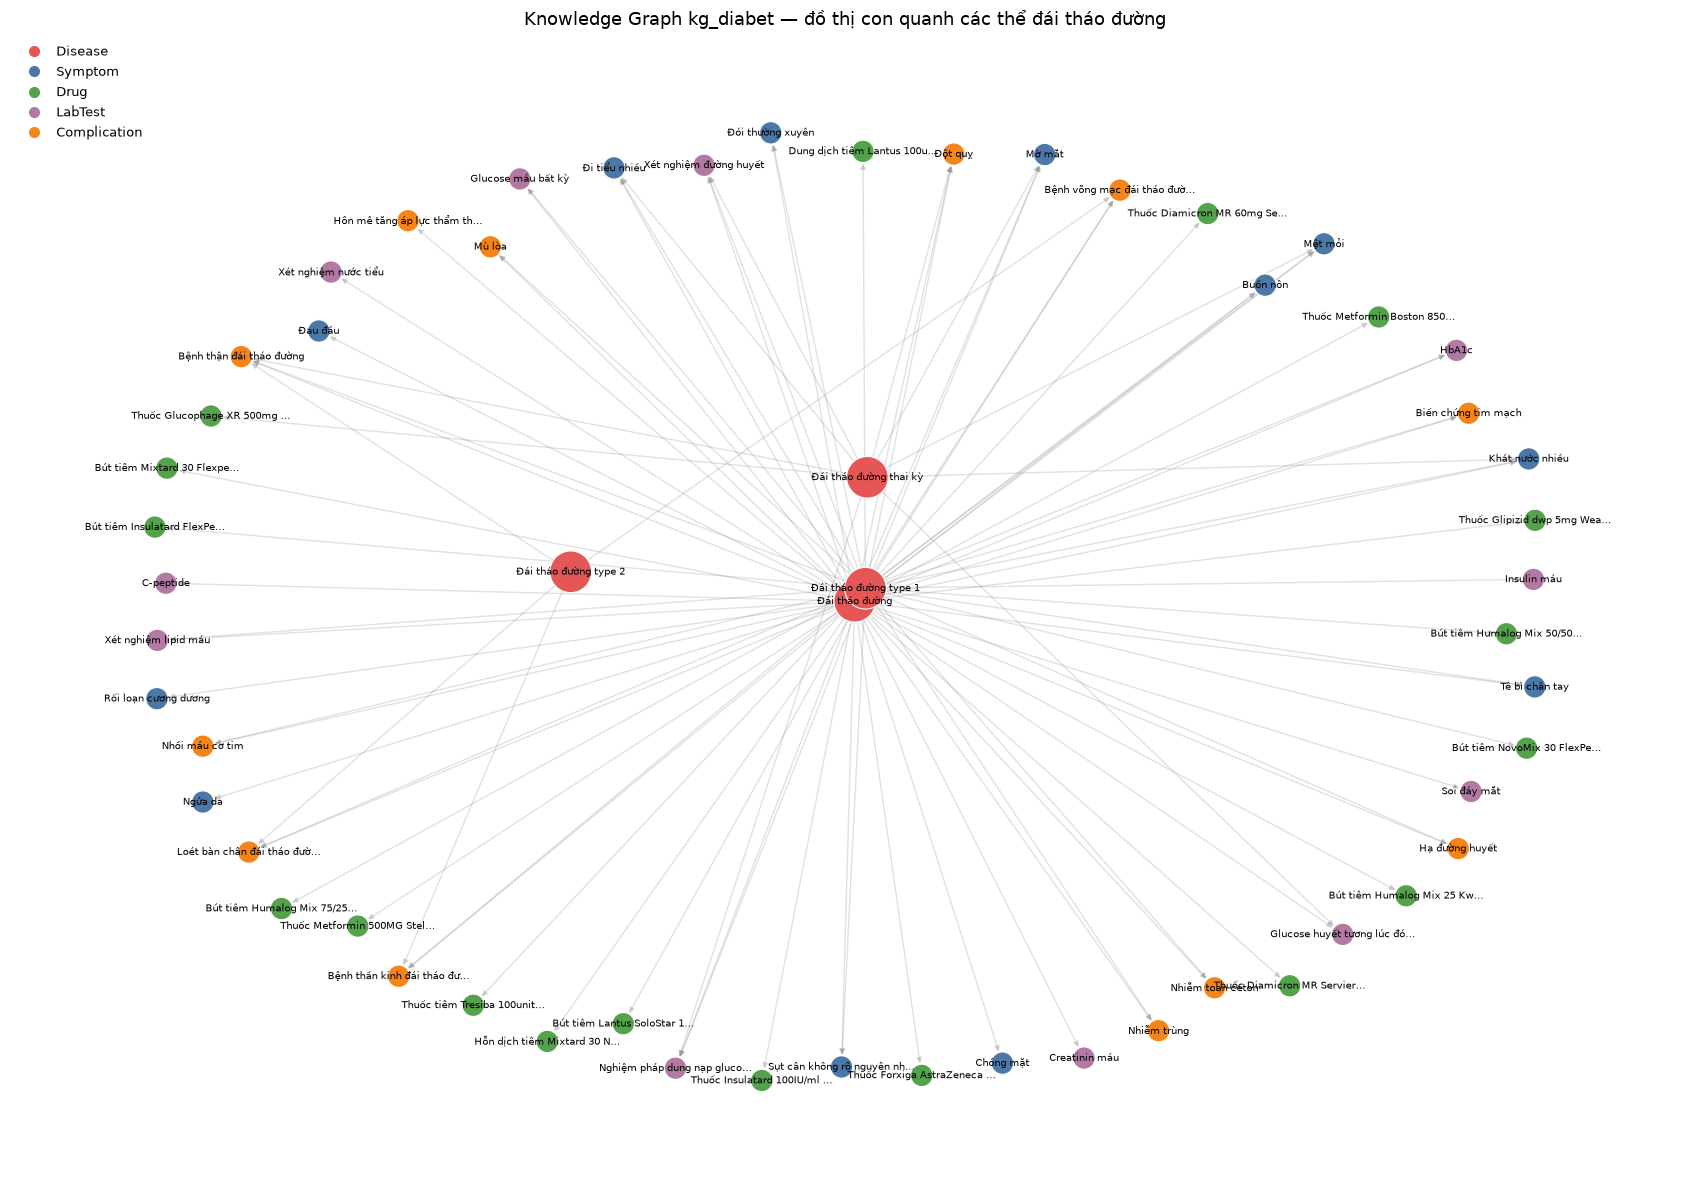

In [34]:
COLORS = {
    "Disease": "#E45756", "Symptom": "#4C78A8", "Drug": "#54A24B",
    "LabTest": "#B279A2", "RiskFactor": "#EECA3B", "Complication": "#F58518",
    "SideEffect": "#9D755D", "DrugCategory": "#72B7B2",
}

G = nx.DiGraph()
for _, row in rows.iterrows():
    G.add_node(row["src"], label="Disease")
    G.add_node(row["dst"], label=row["dst_label"])
    G.add_edge(row["src"], row["dst"], rel=row["rel"])

pos = nx.spring_layout(G, k=0.75, seed=42, iterations=120)
node_colors = [COLORS.get(G.nodes[n]["label"], "#BAB0AC") for n in G.nodes]
node_sizes  = [900 if G.nodes[n]["label"] == "Disease" else 260 for n in G.nodes]

plt.figure(figsize=(17, 12))
nx.draw_networkx_edges(G, pos, alpha=0.25, arrowsize=8, edge_color="#888")
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes,
                       edgecolors="white", linewidths=0.8)
nx.draw_networkx_labels(G, pos, font_size=7,
                        labels={n: (n[:26] + "…" if len(n) > 26 else n) for n in G.nodes})

handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=9,
                      markerfacecolor=c, markeredgecolor="white", label=l)
           for l, c in COLORS.items() if any(G.nodes[n]["label"] == l for n in G.nodes)]
plt.legend(handles=handles, loc="upper left", frameon=False, fontsize=9)
plt.title("Knowledge Graph kg_diabet — đồ thị con quanh các thể đái tháo đường", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()

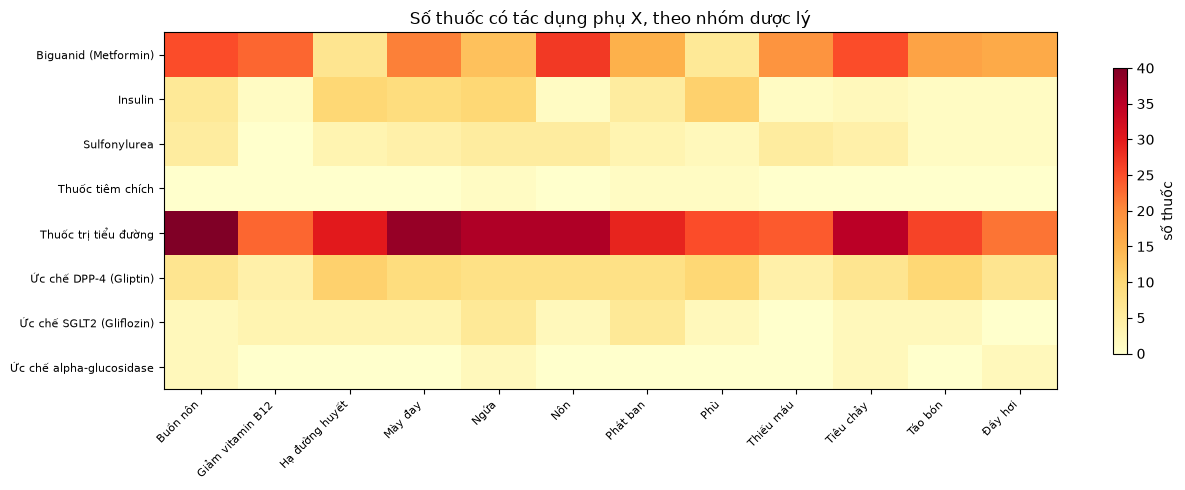

In [35]:
# Heatmap: tần suất tác dụng phụ theo nhóm dược lý
heat = cypher_df("""
    MATCH (cat:DrugCategory)<-[:BELONGS_TO]-(d:Drug)-[:HAS_SIDE_EFFECT]->(se:SideEffect)
    RETURN cat.name AS category, se.name AS side_effect, count(DISTINCT d) AS n
""")

if not heat.empty:
    top_cat = heat.groupby("category")["n"].sum().nlargest(8).index
    top_se  = heat.groupby("side_effect")["n"].sum().nlargest(12).index
    pivot = (heat[heat["category"].isin(top_cat) & heat["side_effect"].isin(top_se)]
             .pivot_table(index="category", columns="side_effect", values="n", fill_value=0))

    fig, ax = plt.subplots(figsize=(13, 5))
    im = ax.imshow(pivot.values, cmap="YlOrRd", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([c[:34] for c in pivot.index], fontsize=8)
    ax.set_title("Số thuốc có tác dụng phụ X, theo nhóm dược lý")
    fig.colorbar(im, ax=ax, shrink=0.8, label="số thuốc")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa đủ dữ liệu để vẽ heatmap.")

---
## Section 9 — Kết luận

**Đã hoàn thành**

* Pipeline 4 bước chạy end-to-end: Long Châu → raw JSON → entities/relations →
  Neo4j `kg-diabet` → Cypher queries.
* Knowledge Graph gồm 8 loại node và 9 loại quan hệ đúng theo schema đề ra, mọi
  node/quan hệ đều mang `source_url` để truy vết về trang gốc.
* Trích xuất tiếng Việt dựa trên từ điển có canonical hoá + underthesea, sinh
  quan hệ theo section ngữ nghĩa và trigger word ở cấp câu.

**Hạn chế**

* Từ điển thực thể được biên soạn thủ công cho miền đái tháo đường; mở rộng sang
  bệnh khác cần bổ sung `lexicon.py`.
* Quan hệ suy ra từ đồng xuất hiện cấp câu nên vẫn có thể lẫn nhiễu; mục
  `contraindications` của Long Châu trộn *chống chỉ định* với *thận trọng* nên
  `CONTRAINDICATED_WITH` chỉ nên coi là **cảnh báo cần kiểm chứng**.
* Giá thuốc thay đổi theo thời điểm scrape; một số sản phẩm không công bố giá.

**Hướng phát triển**

* Dùng LLM để trích quan hệ ở những câu phức mà luật bỏ sót, rồi đối chiếu với
  kết quả từ điển để tăng recall mà vẫn kiểm soát được precision.
* Liên kết node với thuật ngữ chuẩn (ICD-10, ATC, SNOMED CT) để hợp nhất với các
  KG y khoa khác.
* Bổ sung trọng số/độ tin cậy cho quan hệ dựa trên số lần xuất hiện và uy tín nguồn.

---

*Dữ liệu chỉ phục vụ học tập và nghiên cứu — không dùng để chẩn đoán hay điều trị.*

In [36]:
driver.close()
print("Đã đóng kết nối Neo4j.")

Đã đóng kết nối Neo4j.
